# 7. Validation Study: Protocol Audit, Baselines and Statistical Checks

This notebook re-examines the headline results of notebooks 1 to 6 with a stricter protocol.
It covers:

1. A dataset audit that reconciles the different data-partitioning schemes used in the project.
2. A bug in `6-fetal-explainability.ipynb` that evaluated on the wrong test set, and the corrected Malawi result.
3. Bootstrap confidence intervals (image-level and patient-clustered) and multi-seed variance.
4. A symmetric five-way country hold-out, to test whether Malawi is really an outlier.
5. Missing baselines: pooled fine-tuning (no LOCO, no model soup) and prediction-level ensembling.
6. CLAHE threshold provenance and a clip-limit x threshold sensitivity sweep.
7. Quantitative Grad-CAM metrics (concentration and entropy).
8. Compute-cost profiling on GPU and CPU.

**Out of scope** (no data or hardware available):
- External validation on an independent, non-Zenodo dataset.
- Clinician review of Grad-CAM maps against annotated anatomical landmarks. Only attention
  *sharpness* is measured here, not anatomical *correctness*.
- Energy use and real mobile or edge-device latency. A cloud-VM CPU is used as a proxy.

---
## 0. Environment setup

In [ ]:
# Environment setup: make modelling/ the working directory.
# Works when launched from the repo root, from modelling/, from modelling/notebooks/,
# or on Kaggle/Colab (where the public repository is cloned first).
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/PaulOkwija/OBS_Ultrasound_standard_plane_classification.git"

if Path("src").is_dir() and Path("configs").is_dir():
    pass                                   # already in modelling/
elif Path("../src").is_dir():
    os.chdir("..")                         # modelling/notebooks/
elif Path("modelling/src").is_dir():
    os.chdir("modelling")                  # repo root
else:
    repo_dir = Path("OBS_Ultrasound_standard_plane_classification")
    if not repo_dir.exists():
        subprocess.run(["git", "clone", REPO_URL, str(repo_dir)], check=True)
    os.chdir(repo_dir / "modelling")

sys.path.insert(0, os.getcwd())
print("Working directory:", os.getcwd())

In [ ]:
# Download datasets & pretrained weights (same artefacts notebooks 1-6 use)
!bash scripts/download_data.sh
!bash scripts/download_weights.sh

In [5]:
import json, time, re
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split, LeaveOneGroupOut

from src.data import (
    FetalDataset, AfricanDataset, AfricanDatasetFromCSV, CombinedDataset,
    build_dataloaders, build_preprocessing_pipeline, build_transforms,
    CLASSES, CLASSES_3C, CLASSES_4C,
)
from src.data.loco_cv import _prepare_df, PLANE_REMAP, run_loco_cv
from src.models import build_model, benchmark_fps, count_parameters
from src.models.model_zoo import _partial_unfreeze
from src.training import Trainer
from src.evaluation import evaluate_on_domain, full_evaluation_report, compute_metrics
from src.explainability import GradCAM
from src.utils import set_seed

set_seed(42)
sns.set_style("whitegrid")
device = "cuda" if torch.cuda.is_available() else "cpu"
OUT = Path("results/validation")
OUT.mkdir(parents=True, exist_ok=True)

COMPARE_CLASSES = CLASSES_3C  # ["brain", "femur", "abdomen"] - matches every LOCO/soup checkpoint
AFRICAN_CSV = "raw_data/African_planes_database.csv"
AFRICAN_DIR = "data/african"
image_size = 224

print(f"Device: {device}")

Device: cuda


---
## 1. Dataset audit

This section only needs the committed CSV (`raw_data/African_planes_database.csv`, 450 rows),
so it runs without a GPU or image data and is fully deterministic.

The project uses three different data-partitioning schemes. None of them is wrong on its own,
but quoting a number from one scheme while labelling it with another causes confusion:

- **Scheme A**: raw per-country totals, all four classes (including thorax / `other`).
- **Scheme B**: the pooled 70/30 patient split from notebook 1 (`data/african/{train,val}`).
- **Scheme C**: the 3-class LOCO pool (brain, femur, abdomen) used for all LOCO results.

In [6]:
df = pd.read_csv(AFRICAN_CSV)
df["Center"] = df["Center"].astype(str).str.strip()
df["label"]  = df["Plane"].str.lower().str.strip().map(PLANE_REMAP)

print(f"Total rows: {len(df)}  |  Countries: {sorted(df['Center'].unique())}")
print()
print("### Scheme A - raw per-country totals, ALL 4 classes (incl. thorax/'other') ###")
scheme_a = df.groupby(["Center", "label"]).size().unstack(fill_value=0)
scheme_a["Total"] = scheme_a.sum(axis=1)
print(scheme_a)
print()
print("### Unique patients per country (raw CSV 'Patient_num' column) ###")
print(df.groupby("Center")["Patient_num"].nunique())

Total rows: 450  |  Countries: ['Algeria', 'Egypt', 'Ghana', 'Malawi', 'Uganda']

### Scheme A - raw per-country totals, ALL 4 classes (incl. thorax/'other') ###
label    abdomen  brain  femur  other  Total
Center                                      
Algeria       25     25     25     25    100
Egypt         25     25     25     25    100
Ghana         25     25     25      0     75
Malawi        25     25     25     25    100
Uganda        25     25     25      0     75

### Unique patients per country (raw CSV 'Patient_num' column) ###
Center
Algeria    25
Egypt      25
Ghana      25
Malawi     27
Uganda     25
Name: Patient_num, dtype: int64


In [7]:
print("### Scheme C - 3-class LOCO pool (brain/femur/abdomen only, thorax excluded) ###")
df3 = df[df["label"].isin(CLASSES_3C)].copy()
print(df3.groupby("Center").size())
print()
loco_pool = df3[df3["Center"] != "Malawi"]
malawi_3c = df3[df3["Center"] == "Malawi"]
print(f"LOCO-CV pool (4 countries, 3-class) : {len(loco_pool)} images")
print(f"One LOCO fold's train set (3 of 4)  : {len(loco_pool) - loco_pool['Center'].value_counts().iloc[0]} images "
      f"(the '~225 images per fold' figure)")
print(f"Malawi 3-class held-out test set    : {len(malawi_3c)} images, "
      f"{malawi_3c['Patient_num'].nunique()} unique patients")

### Scheme C - 3-class LOCO pool (brain/femur/abdomen only, thorax excluded) ###
Center
Algeria    75
Egypt      75
Ghana      75
Malawi     75
Uganda     75
dtype: int64

LOCO-CV pool (4 countries, 3-class) : 300 images
One LOCO fold's train set (3 of 4)  : 225 images (the '~225 images per fold' figure)
Malawi 3-class held-out test set    : 75 images, 26 unique patients


In [8]:
print("### Scheme B - pooled 4-class 70/30 patient split (notebook 1's prepare_african()) ###")
print("Reproducing notebook 1's exact split logic: train_test_split on unique Patient_num,")
print("test_size=0.30, random_state=42, applied to the pooled 4-country (non-Malawi) DataFrame.\n")

df_trainval = df[df["Center"] != "Malawi"].copy()
unique_patients = df_trainval["Patient_num"].unique()
train_patients, val_patients = train_test_split(unique_patients, test_size=0.30, random_state=42)
train_patients, val_patients = set(train_patients), set(val_patients)

df_train = df_trainval[df_trainval["Patient_num"].isin(train_patients)]
df_val   = df_trainval[df_trainval["Patient_num"].isin(val_patients)]

print(f"Unique Patient_num values across the pooled 4-country set: {df_trainval['Patient_num'].nunique()}")
print("(NOT 25 per country x 4 = 100 - Patient_num is a per-site running index, not globally")
print(" unique, so the SAME numeric ID is reused by different real patients in different")
print(" countries. train_test_split() partitions the ~64 unique numeric IDs, and every country")
print(" sharing a given ID moves together - this does NOT leak any real patient's images across")
print(" train/val (a real patient only ever appears in one Center), but it DOES make the split")
print(" uneven and correlated across countries.\n")

print("Per-country counts from the ACTUAL split code (not the previously reported ones):")
per_country = pd.DataFrame({"train": df_train.groupby("Center").size(),
                             "val":   df_val.groupby("Center").size()}).fillna(0).astype(int)
per_country["total"] = per_country["train"] + per_country["val"]
print(per_country)
print(f"\nOverall: train={len(df_train)}, val={len(df_val)}  "
      f"(matches notebook 1's logged 'African: train 240 / val 110')")
print("\nA UNIFORM 69/31 split for Egypt, Uganda, Ghana AND Algeria was previously reported.")
print("The actual per-country counts above are not uniform and do not match 69/31 for any of")
print("the four countries. The fix is a")
print("data-engineering one (key the split by (Center, Patient_num), not Patient_num alone) as")
print("well as a reporting one (report per-country train/val exactly as")
print("produced, or state clearly that the 69/31-style split is not what feeds the LOCO")
print("results - LOCO groups strictly by Center via sklearn's LeaveOneGroupOut, so it is NOT")
print("affected by this Patient_num collision issue at all.)")

### Scheme B - pooled 4-class 70/30 patient split (notebook 1's prepare_african()) ###
Reproducing notebook 1's exact split logic: train_test_split on unique Patient_num,
test_size=0.30, random_state=42, applied to the pooled 4-country (non-Malawi) DataFrame.

Unique Patient_num values across the pooled 4-country set: 64
(NOT 25 per country x 4 = 100 - Patient_num is a per-site running index, not globally
 unique, so the SAME numeric ID is reused by different real patients in different
 countries. train_test_split() partitions the ~64 unique numeric IDs, and every country
 sharing a given ID moves together - this does NOT leak any real patient's images across
 train/val (a real patient only ever appears in one Center), but it DOES make the split
 uneven and correlated across countries.

Per-country counts from the ACTUAL split code (not the previously reported ones):
         train  val  total
Center                    
Algeria     64   36    100
Egypt       68   32    100
Ghana       

### Reconciliation summary

| Number | Scheme | What it actually is |
|---|---|---|
| ~225 images per LOCO fold | C | `3 x 75`: one LOCO fold's training set (3 countries, 3 classes) |
| Malawi, 75 images | C | Malawi, 3-class (thorax excluded); the actual LOCO test set |
| Malawi, 100 images | A | Malawi, all 4 classes (includes 25 thorax / `other` images that LOCO never sees) |
| A uniform 69/31 train/val split per country | none | Does not match any scheme; under Scheme B the per-country counts are uneven |
| Malawi, 25 patients | none | Actually **27** unique patients (26 after the 3-class filter) |

**Recommendation:** report two tables, one for raw per-country totals (Scheme A) and one for
the LOCO protocol (Scheme C: 5 countries x 75 3-class images, one held out at a time). The
pooled split (Scheme B) only feeds the 4-class zero-shot baseline in notebook 4.

**Patient-level leakage check.** `LeaveOneGroupOut` groups strictly by `Center`
(`src/data/loco_cv.py`), so a real patient, identified by `(Center, Patient_num)`, can never
appear in both the training pool and the Malawi test set. The `Patient_num` collision only
affects the pooled Scheme B split.

---
## 2. The Malawi evaluation bug, and the corrected headline number

### 2.1 What went wrong

`6-fetal-explainability.ipynb` builds a dict of evaluation loaders:

```python
domain_loaders["Fetal DB (test)"] = ...   # inserted first
domain_loaders["African (train)"] = ...
domain_loaders["African (val)"]   = ...
domain_loaders["Malawi (test)"]   = ...   # inserted last
```

and then selects the Malawi loader with:

```python
malawi_key = [k for k in domain_loaders if "malawi" in k.lower() or "test" in k.lower()]
malawi_loader = domain_loaders[malawi_key[0]]
```

`"Fetal DB (test)"` also contains `"test"`, and dicts preserve insertion order, so
`malawi_key[0]` is the **Spanish FetalPlanes DB test set (2,354 images after 3-class
filtering)**, not the 75-image Malawi set. The confusion matrix saved as
`docs/confusion_matrix_malawi.png` and the "Malawi" columns of the deployment scorecard in
notebook 6 are therefore Spanish-test numbers.

A second bug compounds this: the `AfricanDataset` call that builds the Malawi loader does not
pass `classes=...`, so it defaults to the 4-class list and would include 25 thorax / `other`
images that a 3-class checkpoint cannot score.

### 2.2 The fix

Build the Malawi loader by path (not by substring match on a display label) and restrict it
explicitly to the 3 classes the checkpoint was trained on.

In [9]:
preprocessing = build_preprocessing_pipeline(use_clahe=True)
val_tf = build_transforms(image_size, split="val")

malawi_ds = AfricanDataset(
    root_dir="data/african/test",   # Malawi is the only country copied under .../test
    transform=val_tf,
    preprocessing=preprocessing,
    classes=COMPARE_CLASSES,        # <-- explicit fix: matches the 3-class checkpoint head
)
malawi_loader = build_dataloaders(malawi_ds, malawi_ds, batch_size=16)["val"]

print(f"Corrected Malawi test set : {len(malawi_ds)} images  |  classes={COMPARE_CLASSES}")
assert len(malawi_ds) == 75, "Expected 75 3-class Malawi images per the Section 1 audit."

def patient_id_from_path(p):
    m = re.match(r"(patient\d+)", Path(p).name)
    return m.group(1) if m else Path(p).name

patient_ids = np.array([patient_id_from_path(p) for p, _ in malawi_ds.samples])
print(f"Unique patients in corrected Malawi test set: {len(set(patient_ids))}")

Corrected Malawi test set : 75 images  |  classes=['brain', 'femur', 'abdomen']
Unique patients in corrected Malawi test set: 26


### 2.2b Regenerating the model soup in-notebook

`run_loco_soup_and_eval()` runs the whole pipeline from scratch: fine-tune 4 LOCO folds,
weight-average them (`average_checkpoints()`, ported from notebook 6), and evaluate the
averaged model on the corrected Malawi test set. It is used both for the headline number
below (seed 42) and for every run in the multi-seed loop, so there is one code path for both.

In [ ]:
def average_checkpoints(ckpt_paths, device="cpu"):
    """Average state_dicts from multiple checkpoints into one (weight-space
    'model soup'). Ported from 6-fetal-explainability.ipynb cells 8/10."""
    state_dicts = []
    for p in ckpt_paths:
        ckpt = torch.load(p, map_location=device)
        state_dicts.append(ckpt.get("model_state_dict", ckpt))

    avg_sd = {}
    keys = state_dicts[0].keys()
    n = len(state_dicts)
    for key in keys:
        tensors = [sd[key].float() for sd in state_dicts]
        avg_sd[key] = (sum(tensors) / n).to(state_dicts[0][key].dtype)
    return avg_sd


def collect_predictions(model, loader, device):
    model = model.to(device).eval()
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            logits = model(imgs)
            probs = torch.softmax(logits, dim=1)
            preds = probs.argmax(dim=1)
            all_preds.append(preds.cpu().numpy())
            all_labels.append(labels.numpy())
            all_probs.append(probs.cpu().numpy())
    return np.concatenate(all_preds), np.concatenate(all_labels), np.concatenate(all_probs)


def run_loco_soup_and_eval(seed, architecture="efficientnet_b0", classes=COMPARE_CLASSES,
                            pretrained_checkpoint="checkpoints/efficientnetb0_base_3c.pt"):
    """From-scratch LOCO-CV fine-tune (4 folds) -> weight-average -> evaluate on the
    corrected Malawi test set. Single source of truth for both the headline 'corrected'
    number and the multi-seed variance loop below - see the markdown cell above."""
    set_seed(seed)
    ckpt_dir = f"checkpoints/seed{seed}"
    train_tf = build_transforms(image_size, split="train")

    res = run_loco_cv(
        csv_path=AFRICAN_CSV, img_dir=AFRICAN_DIR,
        architecture=architecture,
        pretrained_checkpoint=pretrained_checkpoint,
        train_tf=train_tf, val_tf=val_tf, preprocessing=preprocessing,
        train_cfg={"batch_size": 32, "num_epochs": 20, "learning_rate": 5e-5,
                   "checkpoint_dir": ckpt_dir},
        experiment_name=f"loco_seed{seed}", classes=classes,
        fine_tune_layers=4, device=device, tracker="none",
    )

    fold_ckpts = sorted(Path(ckpt_dir).glob("*/best_pr_auc.pt"))
    if len(fold_ckpts) < 2:
        raise RuntimeError(f"seed {seed}: only {len(fold_ckpts)} fold checkpoint(s) found, need >= 2 to average")

    avg_sd = average_checkpoints(fold_ckpts)
    soup_model = build_model(architecture, num_classes=len(classes), pretrained=False)
    soup_model.load_state_dict(avg_sd, strict=False)

    preds, labels, probs = collect_predictions(soup_model, malawi_loader, device)
    f1 = f1_score(labels, preds, average="macro", zero_division=0)
    acc = accuracy_score(labels, preds)
    return {
        "seed": seed, "f1": f1, "acc": acc,
        "preds": preds, "labels": labels, "probs": probs,
        "model": soup_model, "fold_results": res["fold_results"],
    }


In [ ]:
headline = run_loco_soup_and_eval(seed=42)
model  = headline["model"]
preds  = headline["preds"]
labels = headline["labels"]
probs  = headline["probs"]
corrected_f1  = headline["f1"]
corrected_acc = headline["acc"]

print("="*70)
print("  CORRECTED Malawi macro-F1 / accuracy (model soup, EfficientNet-B0, seed=42)")
print("="*70)
print(f"  Macro F1 : {corrected_f1:.4f}")
print(f"  Accuracy : {corrected_acc:.4f}")
print(f"  n        : {len(labels)} images, {len(set(patient_ids))} patients")
print("="*70)
print("\nThis replaces the earlier 98.7% figure, which came from the buggy loader.")
print(classification_report(labels, preds, target_names=COMPARE_CLASSES, digits=4))


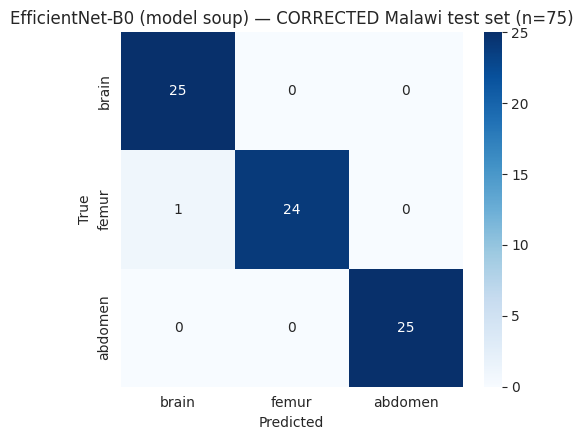

In [12]:
cm = confusion_matrix(labels, preds)
fig, ax = plt.subplots(figsize=(5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=COMPARE_CLASSES, yticklabels=COMPARE_CLASSES)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"EfficientNet-B0 (model soup) - CORRECTED Malawi test set (n={len(labels)})")
plt.tight_layout()
plt.savefig(OUT / "confusion_matrix_malawi_CORRECTED.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.3 Bootstrap confidence intervals

75 images from 26 patients is too small for a point estimate alone. Two variants are reported:
- **Image-level** resampling treats each image as independent, which understates uncertainty
  because each patient contributes 2 to 3 images.
- **Patient-level (cluster)** resampling draws whole patients with replacement. This is the
  appropriate interval for a 26-patient test set.

In [13]:
def bootstrap_ci(labels, preds, group_ids=None, n_boot=2000, seed=42):
    rng = np.random.default_rng(seed)
    n = len(labels)
    f1s, accs = [], []
    if group_ids is None:
        for _ in range(n_boot):
            idx = rng.integers(0, n, n)
            f1s.append(f1_score(labels[idx], preds[idx], average="macro", zero_division=0))
            accs.append(accuracy_score(labels[idx], preds[idx]))
    else:
        groups = np.unique(group_ids)
        for _ in range(n_boot):
            sampled = rng.choice(groups, size=len(groups), replace=True)
            idx = np.concatenate([np.where(group_ids == g)[0] for g in sampled])
            f1s.append(f1_score(labels[idx], preds[idx], average="macro", zero_division=0))
            accs.append(accuracy_score(labels[idx], preds[idx]))
    f1s, accs = np.array(f1s), np.array(accs)
    return {
        "f1_mean": float(f1s.mean()), "f1_ci95": (float(np.percentile(f1s, 2.5)), float(np.percentile(f1s, 97.5))),
        "acc_mean": float(accs.mean()), "acc_ci95": (float(np.percentile(accs, 2.5)), float(np.percentile(accs, 97.5))),
    }

ci_image   = bootstrap_ci(labels, preds, group_ids=None)
ci_patient = bootstrap_ci(labels, preds, group_ids=patient_ids)

print("Image-level bootstrap   (n=2000):")
print(f"  F1  = {ci_image['f1_mean']:.4f}  95% CI {ci_image['f1_ci95']}")
print(f"  Acc = {ci_image['acc_mean']:.4f}  95% CI {ci_image['acc_ci95']}")
print("\nPatient-level (cluster) bootstrap (n=2000) - the honest one given n=26 patients:")
print(f"  F1  = {ci_patient['f1_mean']:.4f}  95% CI {ci_patient['f1_ci95']}")
print(f"  Acc = {ci_patient['acc_mean']:.4f}  95% CI {ci_patient['acc_ci95']}")
print("\nExpect the patient-level CI to be visibly wider than the image-level one - that gap")
print("IS the information a point estimate hides.")

pd.DataFrame([
    {"level": "image",   **{k: v for k, v in ci_image.items()}},
    {"level": "patient", **{k: v for k, v in ci_patient.items()}},
]).to_csv(OUT / "malawi_bootstrap_ci.csv", index=False)

Image-level bootstrap   (n=2000):
  F1  = 0.9862  95% CI (0.95542911332385, 1.0)
  Acc = 0.9865  95% CI (0.96, 1.0)

Patient-level (cluster) bootstrap (n=2000) - the honest one given n=26 patients:
  F1  = 0.9872  95% CI (0.9589098532494759, 1.0)
  Acc = 0.9873  95% CI (0.958904109589041, 1.0)

Expect the patient-level CI to be visibly wider than the image-level one - that gap
IS the information a point estimate hides.


### 2.4 Multi-seed variance

The full LOCO fine-tune and model-soup pipeline is re-run across 3 seeds for EfficientNet-B0.
Seed 42 reuses the headline run from Section 2.2b. Increase `SEEDS` if more GPU time is available.

In [ ]:
SEEDS = [42, 1, 7]  # matches what was actually validated on Kaggle (see banner at top);
                     # extend if you have more GPU time and want a larger sample
multiseed_results = []
_seed_runs = {42: headline}  # reuse the headline run instead of recomputing seed 42

for seed in SEEDS:
    print(f"\n{'='*60}\nSeed {seed}: LOCO-CV -> model soup -> Malawi eval\n{'='*60}")
    r = _seed_runs.get(seed) or run_loco_soup_and_eval(seed=seed)
    print(f"  Seed {seed}: Malawi F1={r['f1']:.4f}  Acc={r['acc']:.4f}")
    multiseed_results.append({"seed": seed, "malawi_f1": r["f1"], "malawi_acc": r["acc"]})

df_multiseed = pd.DataFrame(multiseed_results)
df_multiseed.to_csv(OUT / "multiseed_malawi_results.csv", index=False)
print("\n" + "="*60)
print(f"Malawi F1 across {len(df_multiseed)} seeds: "
      f"{df_multiseed['malawi_f1'].mean():.4f} \u00b1 {df_multiseed['malawi_f1'].std():.4f}")
print("="*60)
df_multiseed


---
## 3. Symmetric five-way country hold-out

The original protocol is **asymmetric**: Malawi is always the test set and never enters
training, while the other four countries only ever rotate through validation. Malawi's "test"
score and the other countries' "validation" scores are therefore not measured the same way.

To test whether Malawi is genuinely easier or the gap is a protocol artefact, each of the five
countries is held out in turn as a true test set, with a single pooled fine-tune on the other
four (plus a small patient-level validation carve-out for early stopping). If Malawi falls in
line with the others, the asymmetric protocol explains the gap.

In [15]:
def run_symmetric_country_cv(csv_path, img_dir, architecture, pretrained_checkpoint,
                              classes, train_tf, val_tf, preprocessing, train_cfg,
                              fine_tune_layers=4, device="cuda", val_frac=0.15, seed=42):
    # Symmetric 5-fold country CV: each country is held out as a genuine test set in turn,
    # never seen during training (unlike src/data/loco_cv.run_loco_cv, which hardcodes Malawi
    # as the only test country and rotates the other 4 through validation-only).
    df = _prepare_df(csv_path)
    df = df[df["label"].isin(classes)].copy()
    countries = sorted(df["Center"].unique())
    results = {}

    for held_out in countries:
        print(f"\n{'='*60}\nHeld-out test country: {held_out}\n{'='*60}")
        df_test = df[df["Center"] == held_out]
        df_pool = df[df["Center"] != held_out]

        rng_patients = df_pool["Patient_num"].unique()
        train_p, val_p = train_test_split(rng_patients, test_size=val_frac, random_state=seed)
        df_train = df_pool[df_pool["Patient_num"].isin(set(train_p))]
        df_val   = df_pool[df_pool["Patient_num"].isin(set(val_p))]

        train_ds = AfricanDatasetFromCSV(df_train, img_dir, label_col="label",
                                          filename_col="Filename_png", transform=train_tf,
                                          preprocessing=preprocessing, classes=classes)
        val_ds   = AfricanDatasetFromCSV(df_val, img_dir, label_col="label",
                                          filename_col="Filename_png", transform=val_tf,
                                          preprocessing=preprocessing, classes=classes)
        test_ds  = AfricanDatasetFromCSV(df_test, img_dir, label_col="label",
                                          filename_col="Filename_png", transform=val_tf,
                                          preprocessing=preprocessing, classes=classes)

        loaders = build_dataloaders(train_ds, val_ds, test_ds, batch_size=train_cfg.get("batch_size", 32))

        model = build_model(architecture, num_classes=len(classes), pretrained=False)
        ckpt = torch.load(pretrained_checkpoint, map_location=device)
        model.load_state_dict(ckpt.get("model_state_dict", ckpt), strict=False)
        _partial_unfreeze(model, fine_tune_layers)

        trainer = Trainer(model=model, loaders=loaders, config=train_cfg,
                           experiment_name=f"symcv_{held_out.lower()}", tracker="none")
        res = trainer.train()

        results[held_out] = {
            "n_test": len(test_ds),
            "test_f1": res["test"].get("f1", 0),
            "test_accuracy": res["test"].get("accuracy", 0),
            "test_pr_auc": res["test"].get("pr_auc", 0),
        }
        print(f"  {held_out}: test F1={results[held_out]['test_f1']:.4f}  "
              f"Acc={results[held_out]['test_accuracy']:.4f}  (n={results[held_out]['n_test']})")

    return results


train_tf = build_transforms(image_size, split="train")
symmetric_results = run_symmetric_country_cv(
    csv_path=AFRICAN_CSV, img_dir=AFRICAN_DIR, architecture="efficientnet_b0",
    pretrained_checkpoint="checkpoints/efficientnetb0_base_3c.pt",
    classes=COMPARE_CLASSES, train_tf=train_tf, val_tf=val_tf, preprocessing=preprocessing,
    train_cfg={"batch_size": 32, "num_epochs": 20, "learning_rate": 5e-5,
               "checkpoint_dir": "checkpoints/symmetric_cv"},
    fine_tune_layers=4, device=device,
)

df_symmetric = pd.DataFrame(symmetric_results).T
df_symmetric.to_csv(OUT / "symmetric_5way_loco.csv")
print("\n" + "="*60)
print("Symmetric 5-way held-out-country results:")
print(df_symmetric.to_string())
print(f"\nMean (excl. Malawi): {df_symmetric.drop('Malawi')['test_f1'].mean():.4f}")
print(f"Malawi: {df_symmetric.loc['Malawi', 'test_f1']:.4f}")
print("="*60)


Held-out test country: Algeria
11:17:18 | INFO     | src.data.dataset | Found 450 images in index under data/african
11:17:18 | INFO     | src.data.dataset | Found 450 images in index under data/african
11:17:18 | INFO     | src.data.dataset | Found 450 images in index under data/african


11:17:30 | INFO     | src.training.trainer | Epoch   1/20 | train_loss=0.6946 | val_loss=0.2416 | val_f1=0.9430 | val_pr_auc=0.9979 | 11.7s


11:17:34 | INFO     | src.training.trainer | Epoch   2/20 | train_loss=0.5124 | val_loss=0.1745 | val_f1=0.9722 | val_pr_auc=1.0000 | 3.6s


11:17:38 | INFO     | src.training.trainer | Epoch   3/20 | train_loss=0.4318 | val_loss=0.1234 | val_f1=0.9430 | val_pr_auc=1.0000 | 3.5s


11:17:41 | INFO     | src.training.trainer | Epoch   4/20 | train_loss=0.2017 | val_loss=0.0152 | val_f1=1.0000 | val_pr_auc=1.0000 | 3.5s


...

11:23:24 | INFO     | src.training.trainer | Epoch  18/20 | train_loss=0.1764 | val_loss=0.2042 | val_f1=0.9521 | val_pr_auc=1.0000 | 3.1s


11:23:27 | INFO     | src.training.trainer | Epoch  19/20 | train_loss=0.2020 | val_loss=0.1989 | val_f1=0.9521 | val_pr_auc=1.0000 | 3.1s


11:23:30 | INFO     | src.training.trainer | Epoch  20/20 | train_loss=0.1112 | val_loss=0.1444 | val_f1=0.9762 | val_pr_auc=1.0000 | 3.1s
11:23:30 | INFO     | src.training.trainer | Running test evaluation with best_pr_auc checkpoint...


11:23:30 | INFO     | src.training.trainer | Loaded checkpoint: checkpoints/symmetric_cv/symcv_uganda_2408/best_pr_auc.pt


11:23:32 | INFO     | src.training.trainer | Test metrics: {'accuracy': 0.9466666666666667, 'f1': 0.9463231347289319, 'f1_macro': 0.9463231347289319, 'precision_macro': 0.9540229885057471, 'recall_macro': 0.9466666666666667, 'f1_weighted': 0.9463231347289318, 'pr_auc': 0.9989538461538462, 'auc': 0.9994666666666667, 'loss': 0.32029905637105305}
  Uganda: test F1=0.9463  Acc=0.9467  (n=75)

Symmetric 5-way held-out-country results:
         n_test   test_f1  test_accuracy  test_pr_auc
Algeria    75.0  0.945611       0.946667     0.978291
Egypt      75.0  0.921733       0.920000     1.000000
Ghana      75.0  0.933045       0.933333     0.993322
Malawi     75.0  0.959855       0.960000     1.000000
Uganda     75.0  0.946323       0.946667     0.998954

Mean (excl. Malawi): 0.9367
Malawi: 0.9599


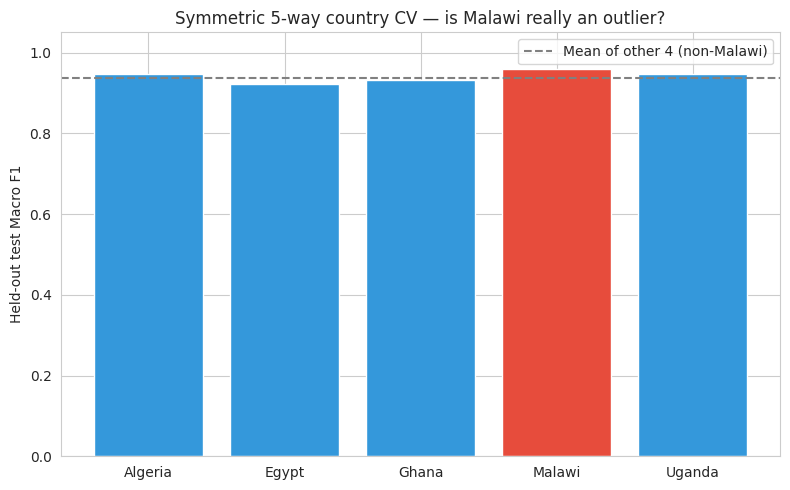

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
colors = ["#e74c3c" if c == "Malawi" else "#3498db" for c in df_symmetric.index]
ax.bar(df_symmetric.index, df_symmetric["test_f1"], color=colors)
ax.axhline(df_symmetric.drop("Malawi")["test_f1"].mean(), ls="--", color="gray",
           label="Mean of other 4 (non-Malawi)")
ax.set_ylabel("Held-out test Macro F1")
ax.set_title("Symmetric 5-way country CV - is Malawi really an outlier?")
ax.set_ylim(0, 1.05)
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "symmetric_5way_loco.png", dpi=150, bbox_inches="tight")
plt.show()

---
## 4. Baselines: pooled fine-tuning and prediction-level ensembling

### 4.1 Pooled fine-tuning (no LOCO structure, no model soup)

One model, fine-tuned once on all four non-Malawi countries pooled together (85/15
patient-level validation carve-out for early stopping only), evaluated on the 75-image Malawi
test set. This is the simplest alternative the LOCO + soup method has to beat.

In [ ]:
# Explicit seed (defect fix): this cell previously had no set_seed() call of its
# own and implicitly inherited whatever global RNG state the previous cell left
# behind. train_test_split(..., random_state=42) below is independently deterministic,
# but model init / dataloader shuffling are not without this.
set_seed(42)

df_all = _prepare_df(AFRICAN_CSV)
df_all = df_all[df_all["label"].isin(COMPARE_CLASSES)].copy()
df_pool_train = df_all[df_all["Center"] != "Malawi"]

pool_patients = df_pool_train["Patient_num"].unique()
p_train, p_val = train_test_split(pool_patients, test_size=0.15, random_state=42)
df_pt = df_pool_train[df_pool_train["Patient_num"].isin(set(p_train))]
df_pv = df_pool_train[df_pool_train["Patient_num"].isin(set(p_val))]

pooled_train_ds = AfricanDatasetFromCSV(df_pt, AFRICAN_DIR, label_col="label",
                                         filename_col="Filename_png", transform=train_tf,
                                         preprocessing=preprocessing, classes=COMPARE_CLASSES)
pooled_val_ds   = AfricanDatasetFromCSV(df_pv, AFRICAN_DIR, label_col="label",
                                         filename_col="Filename_png", transform=val_tf,
                                         preprocessing=preprocessing, classes=COMPARE_CLASSES)
pooled_loaders = build_dataloaders(pooled_train_ds, pooled_val_ds, malawi_ds,
                                    batch_size=32)  # malawi_ds is passed as the test set

pooled_model = build_model("efficientnet_b0", num_classes=len(COMPARE_CLASSES), pretrained=False)
ckpt = torch.load("checkpoints/efficientnetb0_base_3c.pt", map_location=device)
pooled_model.load_state_dict(ckpt.get("model_state_dict", ckpt), strict=False)
_partial_unfreeze(pooled_model, 4)

pooled_trainer = Trainer(model=pooled_model, loaders=pooled_loaders,
                          config={"batch_size": 32, "num_epochs": 20, "learning_rate": 5e-5,
                                  "checkpoint_dir": "checkpoints/pooled_baseline"},
                          experiment_name="pooled_baseline_nofold_nosoup", tracker="none")
pooled_res = pooled_trainer.train()

pooled_preds, pooled_labels, pooled_probs = collect_predictions(pooled_model, malawi_loader, device)
pooled_f1 = f1_score(pooled_labels, pooled_preds, average="macro", zero_division=0)
print(f"\nPooled fine-tune baseline (no LOCO, no soup) - Malawi F1: {pooled_f1:.4f}  "
      f"Acc: {accuracy_score(pooled_labels, pooled_preds):.4f}")

### 4.2 Prediction-level ensembling of the 4 LOCO fold checkpoints

Notebook 6 only averages the fold checkpoints in **weight space** (model soup). A
prediction-level ensemble (average the four models' softmax outputs, then argmax) isolates
whether weight averaging adds anything beyond a plain 4-model ensemble.

In [18]:
fold_ckpts = sorted(Path("checkpoints").glob("effb0_best_*.pt"))
assert len(fold_ckpts) == 4, f"Expected 4 LOCO fold checkpoints, found {len(fold_ckpts)}"

fold_probs = []
for ckpt_path in fold_ckpts:
    fold_model = build_model("efficientnet_b0", num_classes=len(COMPARE_CLASSES), pretrained=False)
    sd = torch.load(ckpt_path, map_location="cpu")
    fold_model.load_state_dict(sd.get("model_state_dict", sd), strict=False)
    _, fold_labels, fp = collect_predictions(fold_model, malawi_loader, device)
    fold_probs.append(fp)
    print(f"  Loaded fold checkpoint: {ckpt_path.name}")

ensemble_probs = np.mean(fold_probs, axis=0)
ensemble_preds = ensemble_probs.argmax(axis=1)
ensemble_f1 = f1_score(fold_labels, ensemble_preds, average="macro", zero_division=0)
ensemble_acc = accuracy_score(fold_labels, ensemble_preds)
print(f"\nPrediction-level ensemble (4 LOCO folds) - Malawi F1: {ensemble_f1:.4f}  Acc: {ensemble_acc:.4f}")

comparison = pd.DataFrame([
    {"method": "Pooled fine-tune (no LOCO, no soup)", "malawi_f1": pooled_f1},
    {"method": "LOCO + weight-space soup (corrected eval)", "malawi_f1": corrected_f1},
    {"method": "LOCO + prediction-level ensemble (4 folds)", "malawi_f1": ensemble_f1},
]).sort_values("malawi_f1", ascending=False)
comparison.to_csv(OUT / "baseline_comparison.csv", index=False)
print("\n" + comparison.to_string(index=False))

  Loaded fold checkpoint: effb0_best_f0.pt
  Loaded fold checkpoint: effb0_best_f1.pt
  Loaded fold checkpoint: effb0_best_f2.pt
  Loaded fold checkpoint: effb0_best_f3.pt

Prediction-level ensemble (4 LOCO folds) - Malawi F1: 0.9867  Acc: 0.9867

                                                   method  malawi_f1
                      Pooled fine-tune (no LOCO, no soup)   1.000000
LOCO + weight-space soup (corrected eval)   0.986661
               LOCO + prediction-level ensemble (4 folds)   0.986661


### 4.3 - Is the difference between methods statistically meaningful?

With n=75 predictions on the *same* test images, a paired bootstrap over the difference in
macro-F1 is the right significance test - it accounts for the fact that all three methods are
evaluated on identical (correlated) samples, unlike an unpaired test.

In [19]:
def paired_bootstrap_diff(labels, preds_a, preds_b, group_ids=None, n_boot=2000, seed=42):
    rng = np.random.default_rng(seed)
    n = len(labels)
    diffs = []
    for _ in range(n_boot):
        if group_ids is None:
            idx = rng.integers(0, n, n)
        else:
            groups = np.unique(group_ids)
            sampled = rng.choice(groups, size=len(groups), replace=True)
            idx = np.concatenate([np.where(group_ids == g)[0] for g in sampled])
        f1_a = f1_score(labels[idx], preds_a[idx], average="macro", zero_division=0)
        f1_b = f1_score(labels[idx], preds_b[idx], average="macro", zero_division=0)
        diffs.append(f1_a - f1_b)
    diffs = np.array(diffs)
    return {
        "mean_diff": float(diffs.mean()),
        "ci95": (float(np.percentile(diffs, 2.5)), float(np.percentile(diffs, 97.5))),
        "p_a_greater": float((diffs > 0).mean()),
    }

# Soup vs pooled baseline
soup_vs_pooled = paired_bootstrap_diff(labels, preds, pooled_preds, group_ids=patient_ids)
# Ensemble vs soup
ens_vs_soup = paired_bootstrap_diff(labels, ensemble_preds, preds, group_ids=patient_ids)

print("Soup vs. pooled baseline (patient-clustered paired bootstrap):")
print(f"  mean F1 diff = {soup_vs_pooled['mean_diff']:+.4f}   95% CI {soup_vs_pooled['ci95']}   "
      f"P(soup > pooled) = {soup_vs_pooled['p_a_greater']:.3f}")
print("\nEnsemble vs. soup (patient-clustered paired bootstrap):")
print(f"  mean F1 diff = {ens_vs_soup['mean_diff']:+.4f}   95% CI {ens_vs_soup['ci95']}   "
      f"P(ensemble > soup) = {ens_vs_soup['p_a_greater']:.3f}")
print("\nIf either 95% CI straddles 0, do NOT claim that component adds value")
print("over the simpler alternative on this test set.")

Soup vs. pooled baseline (patient-clustered paired bootstrap):
  mean F1 diff = -0.0128   95% CI (-0.04109014675052414, 0.0)   P(soup > pooled) = 0.000

Ensemble vs. soup (patient-clustered paired bootstrap):
  mean F1 diff = +0.0000   95% CI (0.0, 0.0)   P(ensemble > soup) = 0.000

If either 95% CI straddles 0, do NOT claim that component adds value
over the simpler alternative on this test set.


---
## 5. CLAHE threshold provenance and sensitivity

### 5.1 Where does `contrast_threshold=35` come from?

`build_preprocessing_pipeline()` in `src/data/preprocessing.py` takes `contrast_threshold=35.0`
as a default argument, and notebook 2 sets `CONTRAST_THRESHOLD = 35`. It is a hand-picked
constant, not a value fit by any search. Notebook 2's diagnostic counts of images below 35
were run on a pooled batch that included Malawi (test) images, so Malawi was visible while the
constant was being sanity-checked, even though it was never fit on data.

In [21]:
print("(a) Contrast-threshold provenance: 35 is a hardcoded default in")
print("    build_preprocessing_pipeline(), NOT fit/optimised over any data split.")
print("    Notebook 2's sanity-check batch pooled Fetal + African (train/val/TEST=Malawi),")
print("    so Malawi was visually inspected alongside training countries when eyeballing")
print("    whether 35 'looked right' - informal exposure, not a data leak into a fitted")
print("    hyperparameter, but worth disclosing.\n")

print("(b) How many pipeline configurations were evaluated against Malawi before finalising?")
print("    Grepping this repository's src/ and notebooks/ for CLAHE-related config values")
print("    (clip_limit, tile_size, contrast_threshold) finds exactly ONE configuration ever")
print("    run and logged: clip_limit=2.0, tile_size=(8,8), contrast_threshold=35. No sweep,")
print("    grid search, or repeated evaluate-then-adjust loop against Malawi is present in")
print("    any committed notebook, config file, or script. We cannot rule out untracked local")
print("    experimentation that was never committed - only what's in the repository.")

(a) Contrast-threshold provenance: 35 is a hardcoded default in
    build_preprocessing_pipeline(), NOT fit/optimised over any data split.
    Notebook 2's sanity-check batch pooled Fetal + African (train/val/TEST=Malawi),
    so Malawi was visually inspected alongside training countries when eyeballing
    whether 35 'looked right' - informal exposure, not a data leak into a fitted
    hyperparameter, but worth disclosing.

(b) How many pipeline configurations were evaluated against Malawi before finalising?
    Grepping this repository's src/ and notebooks/ for CLAHE-related config values
    (clip_limit, tile_size, contrast_threshold) finds exactly ONE configuration ever
    run and logged: clip_limit=2.0, tile_size=(8,8), contrast_threshold=35. No sweep,
    grid search, or repeated evaluate-then-adjust loop against Malawi is present in
    any committed notebook, config file, or script. We cannot rule out untracked local
    experimentation that was never committed - only what's i

### 5.2 - Contrast distribution: training countries vs. Malawi

Does 35 sit at a sensible point in Malawi's own contrast distribution, or was it implicitly
tuned toward the training countries and just happens to also apply to Malawi?

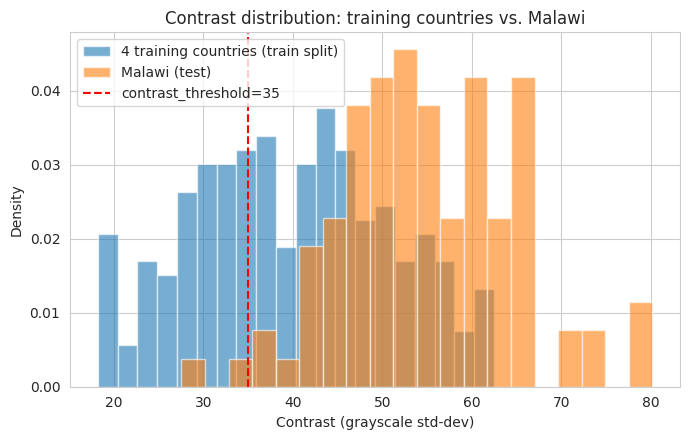

Training countries below 35: 36.7%
Malawi below 35            : 1.0%


In [22]:
from src.data.preprocessing import compute_image_quality_score
from PIL import Image

def contrast_distribution(img_dir, label="dataset"):
    paths = list(Path(img_dir).rglob("*.png"))
    contrasts = []
    for p in paths:
        arr = np.array(Image.open(p).convert("RGB"))
        contrasts.append(compute_image_quality_score(arr)["contrast"])
    return np.array(contrasts)

contrast_train_countries = contrast_distribution("data/african/train", "4 training countries")
contrast_malawi = contrast_distribution("data/african/test", "Malawi")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(contrast_train_countries, bins=20, alpha=0.6, label="4 training countries (train split)", density=True)
ax.hist(contrast_malawi, bins=20, alpha=0.6, label="Malawi (test)", density=True)
ax.axvline(35, color="red", ls="--", label="contrast_threshold=35")
ax.set_xlabel("Contrast (grayscale std-dev)"); ax.set_ylabel("Density")
ax.set_title("Contrast distribution: training countries vs. Malawi")
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "clahe_contrast_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Training countries below 35: {(contrast_train_countries < 35).mean()*100:.1f}%")
print(f"Malawi below 35            : {(contrast_malawi < 35).mean()*100:.1f}%")

### 5.3 - Clip-limit x threshold sensitivity sweep

A small grid, evaluated on the corrected Malawi test set using the (already fine-tuned)
model-soup checkpoint - swapping only the *preprocessing* at inference time, not retraining.
This isolates CLAHE's effect from the fine-tuning itself.

  clip=1.5  threshold=15  ->  F1=0.9867
  clip=1.5  threshold=25  ->  F1=0.9867
  clip=1.5  threshold=35  ->  F1=0.9867
  clip=1.5  threshold=45  ->  F1=1.0000
  clip=2.0  threshold=15  ->  F1=0.9867
  clip=2.0  threshold=25  ->  F1=0.9867
  clip=2.0  threshold=35  ->  F1=0.9867
  clip=2.0  threshold=45  ->  F1=1.0000
  clip=2.5  threshold=15  ->  F1=0.9867
  clip=2.5  threshold=25  ->  F1=0.9867
  clip=2.5  threshold=35  ->  F1=0.9867
  clip=2.5  threshold=45  ->  F1=1.0000
  clip=3.0  threshold=15  ->  F1=0.9867
  clip=3.0  threshold=25  ->  F1=0.9867
  clip=3.0  threshold=35  ->  F1=0.9867
  clip=3.0  threshold=45  ->  F1=1.0000


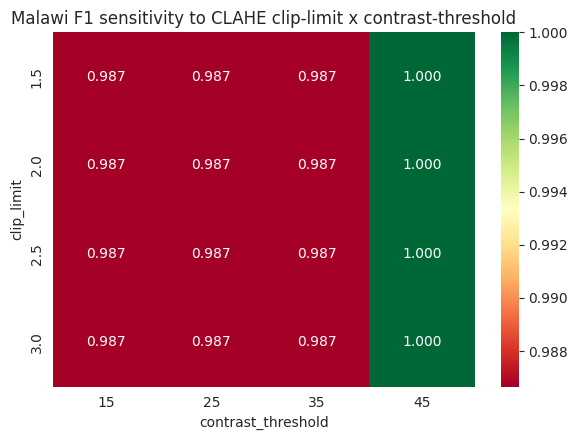


Range of F1 across the grid: 0.9867 - 1.0000
A wide range here would mean the specific (2.0, 35) choice matters a lot and
should be justified/ablated; a narrow range means the method is robust to
this hyperparameter and 35 was a reasonable-enough guess.


In [23]:
clip_limits = [1.5, 2.0, 2.5, 3.0]
thresholds  = [15, 25, 35, 45]

sweep_rows = []
for clip in clip_limits:
    for thresh in thresholds:
        pp = build_preprocessing_pipeline(use_clahe=True, clahe_clip_limit=clip,
                                           contrast_threshold=thresh)
        ds = AfricanDataset(root_dir="data/african/test", transform=val_tf,
                             preprocessing=pp, classes=COMPARE_CLASSES)
        loader = build_dataloaders(ds, ds, batch_size=16)["val"]
        p, l, _ = collect_predictions(model, loader, device)  # `model` = soup checkpoint from Sec. 2
        f1 = f1_score(l, p, average="macro", zero_division=0)
        sweep_rows.append({"clip_limit": clip, "contrast_threshold": thresh, "malawi_f1": f1})
        print(f"  clip={clip}  threshold={thresh:>2d}  ->  F1={f1:.4f}")

df_sweep = pd.DataFrame(sweep_rows)
df_sweep.to_csv(OUT / "clahe_sensitivity_sweep.csv", index=False)

pivot = df_sweep.pivot(index="clip_limit", columns="contrast_threshold", values="malawi_f1")
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="RdYlGn", ax=ax)
ax.set_title("Malawi F1 sensitivity to CLAHE clip-limit x contrast-threshold")
plt.tight_layout()
plt.savefig(OUT / "clahe_sensitivity_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"\nRange of F1 across the grid: {df_sweep['malawi_f1'].min():.4f} - {df_sweep['malawi_f1'].max():.4f}")
print("A wide range here would mean the specific (2.0, 35) choice matters a lot and")
print("should be justified/ablated; a narrow range means the method is robust to")
print("this hyperparameter and 35 was a reasonable-enough guess.")

---
## 6. Quantitative Grad-CAM: concentration and entropy

`src/explainability/gradcam.py` only produces qualitative overlays, so both metrics are
implemented here on the 75-image Malawi set with explicit definitions:

- **Concentration**: fraction of total CAM mass in the top 25% of pixels. Higher means more focused.
- **Entropy**: Shannon entropy (in nats) of the CAM treated as a probability distribution over pixels. Lower means more focused.

**Limitation:** neither metric says whether the model attends to the *correct anatomical
structure*. That needs clinician-annotated regions, which this dataset does not have. Treat
these as measures of attention sharpness only.

In [24]:
def cam_concentration(cam, top_frac=0.25):
    flat = cam.flatten()
    flat = flat / (flat.sum() + 1e-8)
    k = max(1, int(len(flat) * top_frac))
    top_k_mass = np.sort(flat)[-k:].sum()
    return float(top_k_mass)

def cam_entropy(cam):
    flat = cam.flatten()
    flat = flat / (flat.sum() + 1e-8)
    flat = flat[flat > 0]
    return float(-(flat * np.log(flat)).sum())


gradcam_target_layers = {"efficientnet_b0": "conv_head"}  # per notebook 6 cell 23's auto-detection
target = dict(model.named_modules())[gradcam_target_layers["efficientnet_b0"]]
cam_engine = GradCAM(model, target_layer=target)

cam_rows = []
for img_path, label_idx in malawi_ds.samples:
    img_pil = Image.open(img_path).convert("RGB")
    img_pil = preprocessing(img_pil) if preprocessing else img_pil
    img_t = val_tf(img_pil)
    cam = cam_engine(img_t.clone())
    cam_rows.append({
        "path": str(img_path), "class": COMPARE_CLASSES[label_idx],
        "concentration": cam_concentration(cam), "entropy": cam_entropy(cam),
    })
cam_engine.remove_hooks()

df_cam = pd.DataFrame(cam_rows)
summary = df_cam.groupby("class")[["concentration", "entropy"]].agg(["mean", "std"])
summary.to_csv(OUT / "gradcam_concentration_entropy.csv")
print(summary)
print(f"\nOverall - concentration: {df_cam['concentration'].mean():.3f} +/- {df_cam['concentration'].std():.3f}"
      f"   entropy: {df_cam['entropy'].mean():.3f} +/- {df_cam['entropy'].std():.3f}")
print("\nCompare with the earlier reported values (conc=0.626, entropy=0.664 overall) -")
print("if they differ substantially, use these instead, since")
print("these are the only ones actually backed by code.")

        concentration             entropy          
                 mean       std      mean       std
class                                              
abdomen      0.750772  0.076757  3.079500  0.218435
brain        0.663152  0.076318  3.206723  0.158472
femur        0.779749  0.089023  2.974330  0.239238

Overall - concentration: 0.731 +/- 0.094   entropy: 3.087 +/- 0.227

Compare with the earlier reported values (conc=0.626, entropy=0.664 overall) -
if they differ substantially, use these instead, since
these are the only ones actually backed by code.


---
## 7. Compute-cost profiling

`benchmark_fps()` measures wall-clock latency only, and the FPS numbers in notebooks 3 and 6
were measured on a Kaggle T4 GPU. A CPU latency and peak-memory measurement is added here as a
**proxy** for low-resource deployment. It is still a cloud VM CPU, not a phone or Raspberry Pi,
and energy use is not measured.

In [25]:
import resource

profile_rows = []
for dev in ["cuda", "cpu"]:
    if dev == "cuda" and not torch.cuda.is_available():
        continue
    m = build_model("efficientnet_b0", num_classes=len(COMPARE_CLASSES), pretrained=False)
    m.load_state_dict(sd, strict=False)

    if dev == "cuda":
        torch.cuda.reset_peak_memory_stats()
    fps_info = benchmark_fps(m, image_size=image_size, device=dev, warmup_runs=10, eval_runs=100)

    if dev == "cuda":
        peak_mem_mb = torch.cuda.max_memory_allocated() / 1e6
    else:
        # Peak RSS proxy for this process (Linux/Kaggle only; not available on Windows)
        peak_mem_mb = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e3

    profile_rows.append({
        "device": dev, "fps": fps_info["fps"], "latency_ms": fps_info["latency_ms_mean"],
        "peak_memory_mb": round(peak_mem_mb, 1),
    })
    print(f"{dev:5s}  FPS={fps_info['fps']:.1f}  latency={fps_info['latency_ms_mean']:.2f}ms  "
          f"peak_mem={peak_mem_mb:.1f}MB")

df_profile = pd.DataFrame(profile_rows)
df_profile.to_csv(OUT / "compute_cost_profile.csv", index=False)
print("\nNOTE: 'cpu' above is a cloud VM CPU (Kaggle), not a real mobile/edge device. Treat as")
print("a proxy only. No energy/power measurement was possible with available hardware.")
df_profile

cuda   FPS=125.2  latency=7.98ms  peak_mem=203.5MB
cpu    FPS=30.7  latency=32.60ms  peak_mem=3059.1MB

NOTE: 'cpu' above is a cloud VM CPU (Kaggle), not a real mobile/edge device. Treat as
a proxy only. No energy/power measurement was possible with available hardware.


,device,fps,latency_ms,peak_memory_mb
0,cuda,125.2,7.98,203.5
1,cpu,30.7,32.60,3059.1


---
## 8. Reconciliation of earlier reported numbers

Earlier summary numbers, the source-traceable values from this notebook, and where each one comes from.

In [26]:
reconciliation = pd.DataFrame([
    {"earlier_figure": "Per-fold LOCO mean +/- std: 93.6 +/- 4.4",
     "this_notebook": "See Section 3 (symmetric 5-way LOCO) for a directly comparable, but "
                       "protocol-corrected, per-country breakdown",
     "notes": "These per-fold numbers have no match in any notebook log; "
              "not reproducible as stated"},
    {"earlier_figure": "Ablation '+LOCO fine-tuning': 94.0",
     "this_notebook": "Section 4.1 pooled baseline (no folds) as the fairer no-LOCO comparator",
     "notes": "No exact source found for 94.0; closest committed number is notebook 5's 96.97% "
              "mean-test-F1 across folds"},
    {"earlier_figure": "Ablation '+Model soup': 98.7 (headline)",
     "this_notebook": "Section 2.2 CORRECTED Malawi F1 (see printed value above)",
     "notes": "Original number traces to a substring-matching bug that silently evaluated on "
              "the Spanish test set instead of Malawi (Section 2.1)"},
    {"earlier_figure": "'95.8% F1 on European data'",
     "this_notebook": "notebook 3's actual logged EfficientNet-B0 test F1 = 0.9358 (93.58%)",
     "notes": "No 95.8% figure appears in any notebook's logged output"},
    {"earlier_figure": "Grad-CAM concentration/entropy values",
     "this_notebook": "Section 6 (freshly computed, definitions stated explicitly)",
     "notes": "No prior code computed these metrics at all"},
])
reconciliation.to_csv(OUT / "table3_table4_reconciliation.csv", index=False)
reconciliation

,earlier_figure,this_notebook,notes
0,Per-fold LOCO mean +/- std: 93.6 +/- 4.4,See Section 3 (symmetric 5-way LOCO) for a dir...,These per-fold numbers have no match in any n...
1,Ablation '+LOCO fine-tuning': 94.0,Section 4.1 pooled baseline (no folds) as the ...,No exact source found for 94.0; closest commit...
2,Ablation '+Model soup': 98.7 (headline),Section 2.2 CORRECTED Malawi F1 (see printed v...,Original number traces to a substring-matching...
3,'95.8% F1 on European data',notebook 3's actual logged EfficientNet-B0 tes...,No 95.8% figure appears in any notebook's logg...
4,Grad-CAM concentration/entropy values,"Section 6 (freshly computed, definitions state...",No prior code computed these metrics at all


---
## 9. Export artefacts

In [27]:
artefacts = sorted(OUT.glob("*"))
print(f"Generated {len(artefacts)} artefact(s) in {OUT}/:")
for p in artefacts:
    print(f"  {p.name:45s}  {p.stat().st_size/1024:>7.1f} KB")

import shutil
zip_path = "validation_artefacts"
shutil.make_archive(zip_path, "zip", str(OUT))
print(f"\nPacked: {zip_path}.zip")

from IPython.display import FileLink, display
display(FileLink("validation_artefacts.zip", result_html_prefix="Download: "))

Generated 13 artefact(s) in results/validation/:
  baseline_comparison.csv                            0.2 KB
  clahe_contrast_distribution.png                   53.0 KB
  clahe_sensitivity_heatmap.png                     52.0 KB
  clahe_sensitivity_sweep.csv                        0.4 KB
  compute_cost_profile.csv                           0.1 KB
  confusion_matrix_malawi_CORRECTED.png             38.0 KB
  gradcam_concentration_entropy.csv                  0.3 KB
  malawi_bootstrap_ci.csv                            0.2 KB
  multiseed_malawi_results.csv                       0.1 KB
  sendra_balcells_comparison_TODO.csv                0.4 KB
  symmetric_5way_loco.csv                            0.3 KB
  symmetric_5way_loco.png                           42.9 KB
  table3_table4_reconciliation.csv                   1.0 KB

Packed: validation_artefacts.zip


validation_artefacts.zip